# Diabetes Progression: which measurements forecast how a patient does next year?

**The question:** 442 patients already living with diabetes had ten simple measurements taken at a baseline visit (age, sex, body-mass index, blood pressure and six blood tests). One year later, doctors scored how much their disease had **progressed**. Which baseline measurements tell us the most about that score, and how well can we forecast it?

> **What this dataset is *not*.** Everyone here already has diabetes. The target is *how much worse things got*, a number from 25 to 346, not a yes/no diagnosis. So this is a **regression** problem (predict a number), not a classification of "at risk / not at risk".

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Look at the data
4. Hypotheses and tests, one measurement at a time
5. Groups and odds ratios
6. Measurements together, and why some of them confuse each other
7. Forecasting with honest cross-validation
8. Takeaways
9. Limitations

**Run it:** `uv run jupyter lab ML/diabetes-risk/diabetes_risk.ipynb`, or *Run All* in any Jupyter. The dataset ships inside scikit-learn, so there is nothing to download.

## 1. 💡 The simple analogy

Think of a **weather forecaster**. Today's gauges (temperature, air pressure, humidity) don't *cause* tomorrow's storm, but some of them are much better storm signals than others, and a forecaster who watches the right two or three gauges can do almost as well as one who watches twenty.

Here the **gauges** are the ten baseline measurements and the **storm** is next year's disease progression. We want to find out:

- which gauges move together with the storm (**statistical tests**),
- which gauges are just copies of each other (**collinearity**), and
- how good a forecast we can make *honestly*, meaning on patients the model has never seen (**cross-validation**).

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed keeps the notebook reproducible, and avoids "magic numbers" buried in the code. With the seed fixed, every bootstrap and every cross-validation split comes out the same each time you run it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

OUT_DIR = Path("outputs")
SEED = 42
N_BOOTSTRAP = 2_000
CV_SPLITS, CV_REPEATS = 5, 10
BMI_EDGES = [0, 24.999, 29.999, np.inf]
BMI_LABELS = ["Under 25", "25 to 29.9", "30 and over"]
TEAL, ORANGE, NAVY, GREY = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)

## 3. Look at the data first

*What:* load the data in **real units**. *Why this matters:* scikit-learn's default version of this dataset has every column shifted and squashed so that it sums to 1. That's fine for a model, but it makes the numbers unreadable: you can't say "a BMI of 30" or "a blood pressure of 100". Passing `scaled=False` gives the original clinical units, so every result below can be explained to a patient.

| Column | What it is | Unit |
|---|---|---|
| `age` | Age at baseline | years |
| `sex` | Sex, coded 1 or 2 (the dataset does not say which is which) | code |
| `bmi` | Body-mass index | kg/m² |
| `bp` | Average blood pressure | mm Hg |
| `s1` | Total serum cholesterol (tc) | mg/dL |
| `s2` | Low-density lipoprotein, "bad" cholesterol (ldl) | mg/dL |
| `s3` | High-density lipoprotein, "good" cholesterol (hdl) | mg/dL |
| `s4` | Total cholesterol ÷ HDL (tch) | ratio |
| `s5` | Probably the log of serum triglycerides (ltg) | log units |
| `s6` | Blood sugar (glu) | mg/dL |
| **`progression`** | **Disease progression one year later (our target)** | score |

In [2]:
def load_data() -> pd.DataFrame:
    """Loads the diabetes dataset in original clinical units.

    Returns:
        DataFrame with the ten baseline features and a ``progression`` column.

    Raises:
        ValueError: If the data does not have the expected 442 rows or has nulls.
    """
    bunch = load_diabetes(as_frame=True, scaled=False)
    df = bunch.data.assign(progression=bunch.target)
    if len(df) != 442 or df.isna().any().any():
        raise ValueError(f"Unexpected data: shape={df.shape}")
    return df


df = load_data()
FEATURES = [c for c in df.columns if c != "progression"]
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [3]:
print(f"Patients: {len(df)}   Missing values: {int(df.isna().sum().sum())}")
print(f"Sex codes: {df['sex'].value_counts().sort_index().to_dict()}")
df.describe().round(1).T

Patients: 442   Missing values: 0
Sex codes: {1.0: 235, 2.0: 207}


,count,mean,std,min,25%,50%,75%,max
age,442.0,48.5,13.1,19.0,38.2,50.0,59.0,79.0
sex,442.0,1.5,0.5,1.0,1.0,1.0,2.0,2.0
bmi,442.0,26.4,4.4,18.0,23.2,25.7,29.3,42.2
bp,442.0,94.6,13.8,62.0,84.0,93.0,105.0,133.0
s1,442.0,189.1,34.6,97.0,164.2,186.0,209.8,301.0
s2,442.0,115.4,30.4,41.6,96.0,113.0,134.5,242.4
s3,442.0,49.8,12.9,22.0,40.2,48.0,57.8,99.0
s4,442.0,4.1,1.3,2.0,3.0,4.0,5.0,9.1
s5,442.0,4.6,0.5,3.3,4.3,4.6,5.0,6.1
s6,442.0,91.3,11.5,58.0,83.2,91.0,98.0,124.0


**How to read this.** There are **442 patients** and no missing values. The sexes are close to balanced (235 coded 1, 207 coded 2). Average BMI is 26.4 (overweight starts at 25, obesity at 30), and progression has a mean of 152 and a median of 140.5 with a wide spread (standard deviation 77).

### Is the target bell-shaped?

*What:* this decides which statistical tests are safe. Many classic tests (t-test, ANOVA) assume roughly bell-shaped data. The **Shapiro-Wilk test** asks: **H₀:** the data came from a normal (bell-shaped) distribution. A small p-value says it did not. We also plot it, because a plot shows *how* it differs, not just *that* it does.

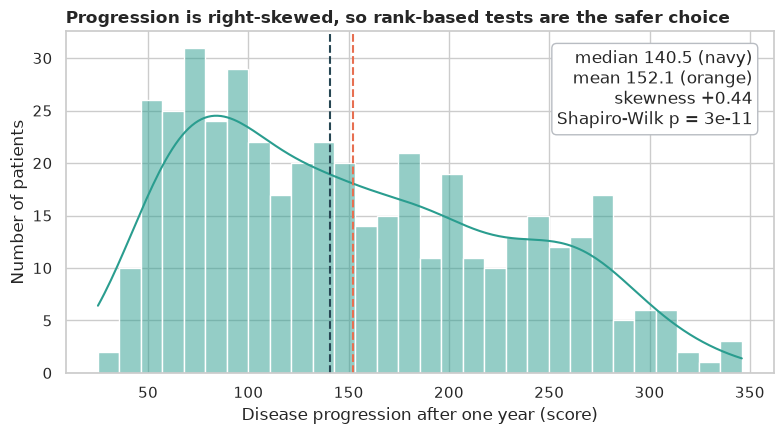

In [4]:
shapiro = stats.shapiro(df["progression"])
skew = stats.skew(df["progression"])

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["progression"], bins=30, kde=True, color=TEAL, ax=ax)
median, mean = df["progression"].median(), df["progression"].mean()
ax.axvline(median, color=NAVY, ls="--")
ax.axvline(mean, color=ORANGE, ls="--")
ax.text(0.97, 0.95,
        f"median {median:.1f} (navy)\nmean {mean:.1f} (orange)\n"
        f"skewness {skew:+.2f}\nShapiro-Wilk p = {shapiro.pvalue:.0e}",
        transform=ax.transAxes, ha="right", va="top",
        bbox={"boxstyle": "round", "fc": "white", "ec": GREY})
ax.set_xlabel("Disease progression after one year (score)")
ax.set_ylabel("Number of patients")
ax.set_title("Progression is right-skewed, so rank-based tests are the safer choice",
             loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "01_progression_distribution.png", dpi=150)
plt.show()

**How to read this.** The histogram leans to the right: there is a long tail of patients with high scores, and the mean (152) sits above the median (140.5). The Shapiro-Wilk p-value is about 3e-11, so we **reject** "this is bell-shaped". With 442 patients the test is very sensitive, and the skewness of +0.44 is moderate, not extreme, but it is enough for us to prefer **rank-based (non-parametric) tests**: they work on the *order* of the values, so they don't care about the shape.

## 4. 🔬 Hypotheses and tests, one measurement at a time

Before looking at any p-values, here are the questions, each with its null (H₀, "nothing is going on") and alternative (Hₐ, "something is"):

| # | Question | H₀ | Hₐ | Test |
|---|---|---|---|---|
| 1 | Does each measurement move with progression? | Spearman ρ = 0 | ρ ≠ 0 | Spearman rank correlation, Holm-corrected over 10 features |
| 2 | Does progression differ across BMI groups? | Same distribution in all 3 groups | At least one group differs | Kruskal-Wallis, then pairwise Mann-Whitney |
| 3 | Does progression differ by sex? | Same average / distribution | Differs | Welch t-test and Mann-Whitney U |
| 4 | Do obese patients have higher odds of above-median progression? | Odds ratio = 1 | OR ≠ 1 | Fisher's exact test |

### Question 1: Spearman correlation for every measurement

**Why Spearman and not Pearson?** Pearson correlation measures how well the points follow a straight line and is easily pulled around by extreme values. Spearman first replaces every value by its **rank** (1st, 2nd, 3rd…) and then correlates the ranks. It catches any "goes up together" trend, straight or curved, and shrugs off outliers. **ρ runs from −1 to +1**; 0 means no relationship.

**Why a bootstrap CI?** A p-value only says "unlikely to be luck". The confidence interval says *how strong* the link plausibly is. We re-draw the patients with replacement 2,000 times, recompute ρ each time, and take the middle 95% of the results.

**Why Holm correction?** We are testing 10 features at once. Test enough things and one will look "significant" by pure luck, like buying more lottery tickets. Holm adjusts the p-values so the chance of *any* false alarm across all ten stays at 5%.

In [5]:
def spearman_with_ci(
    x: np.ndarray, y: np.ndarray, rng: np.random.Generator, n_boot: int = N_BOOTSTRAP
) -> tuple[float, float, float, float]:
    """Spearman correlation with a bootstrap 95% confidence interval.

    Args:
        x: Feature values.
        y: Target values.
        rng: Random generator, so the result is reproducible.
        n_boot: Number of bootstrap resamples.

    Returns:
        rho, p-value, CI lower bound, CI upper bound.
    """
    rho, p = stats.spearmanr(x, y)
    idx = rng.integers(0, len(x), (n_boot, len(x)))
    boot = [stats.spearmanr(x[i], y[i])[0] for i in idx]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return float(rho), float(p), float(lo), float(hi)


progression = df["progression"].to_numpy()
corr = pd.DataFrame(
    {f: spearman_with_ci(df[f].to_numpy(), progression, rng) for f in FEATURES},
    index=["rho", "p", "ci_low", "ci_high"],
).T
corr["p_holm"] = multipletests(corr["p"], method="holm")[1]
corr = corr.sort_values("rho")
corr.style.format({"rho": "{:+.2f}", "p": "{:.1e}", "ci_low": "{:+.2f}", "ci_high": "{:+.2f}",
                   "p_holm": "{:.1e}"})

,rho,p,ci_low,ci_high,p_holm
s3,-0.41,2.4e-19,-0.48,-0.33,1.4e-18
sex,+0.04,4.3e-01,-0.06,+0.13,4.3e-01
s2,+0.20,3.4e-05,+0.11,+0.28,8.4e-05
age,+0.20,2.8e-05,+0.11,+0.28,8.4e-05
s1,+0.23,7.8e-07,+0.15,+0.32,3.1e-06
s6,+0.35,3.0e-14,+0.27,+0.43,1.5e-13
bp,+0.42,6.0e-20,+0.33,+0.50,4.2e-19
s4,+0.45,2.6e-23,+0.38,+0.52,2.1e-22
bmi,+0.56,4.6e-38,+0.49,+0.62,4.1e-37
s5,+0.59,1.1e-42,+0.53,+0.64,1.1e-41


**How to read this.** (Sorted from most negative to most positive.)

- **Nine of the ten measurements are significantly linked to progression** after Holm correction (p_holm < 0.001 for all nine).
- **The strongest links are `s5` (ρ ≈ +0.59) and `bmi` (ρ ≈ +0.56)**, then `s4` (+0.45), `bp` (+0.42) and `s3` (−0.41, the "good" cholesterol: *higher* HDL goes with *less* progression). By the usual rules of thumb, |ρ| of 0.3 to 0.5 is a moderate link and about 0.6 is fairly strong.
- **`age`, `s1` and `s2` are weaker** (ρ ≈ +0.20 to +0.23): real, but small.
- **`sex` shows no link on its own** (ρ = +0.04, p = 0.43): its confidence interval comfortably includes 0. **Fail to reject H₀.** Hold on to this; sex has a surprise in store in section 6.

Remember: correlation is not causation. These are *signals*, not *causes*.

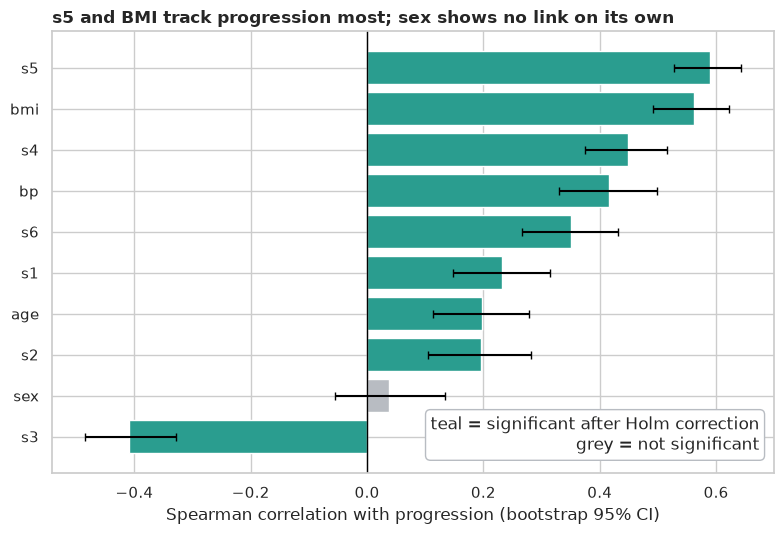

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.5))
significant = corr["p_holm"] < 0.05
ypos = np.arange(len(corr))
ax.barh(ypos, corr["rho"], color=np.where(significant, TEAL, GREY))
ax.errorbar(corr["rho"], ypos, xerr=[corr["rho"] - corr["ci_low"], corr["ci_high"] - corr["rho"]],
            fmt="none", ecolor="black", capsize=3)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(ypos, corr.index)
ax.set_xlabel("Spearman correlation with progression (bootstrap 95% CI)")
ax.text(0.98, 0.04, "teal = significant after Holm correction\ngrey = not significant",
        transform=ax.transAxes, ha="right", va="bottom",
        bbox={"boxstyle": "round", "fc": "white", "ec": GREY})
ax.set_title("s5 and BMI track progression most; sex shows no link on its own",
             loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_spearman_by_feature.png", dpi=150)
plt.show()

**How to read this.** Each bar is a correlation and each black whisker is its 95% CI. Teal bars are significant after correction. The whiskers on `s5` and `bmi` sit well away from 0 and from the weaker group, while `sex` is a tiny bar straddling 0. The negative bar is `s3`: protective, not harmful.

## 5. Groups and odds ratios

### Question 2: BMI groups (Kruskal-Wallis)

*What:* split patients into the standard WHO BMI bands (under 25, 25 to 29.9 for overweight, 30 and over for obese) and compare their progression. **Why Kruskal-Wallis?** It is the rank-based version of one-way ANOVA: it compares three or more groups without assuming bell shapes. **H₀:** all three groups have the same distribution of progression. **Hₐ:** at least one group differs. Its effect size is **ε²** (epsilon-squared; roughly 0.01 small, 0.06 medium, 0.14 large). A significant Kruskal-Wallis only says "*some* group differs", so we follow with pairwise Mann-Whitney tests, again Holm-corrected, to see *which* ones.

### Question 3: Sex (t-test and Mann-Whitney side by side)

*What:* compare progression between the two sex codes. We run **both** a Welch t-test (compares averages; "Welch" means it doesn't need equal spreads) and a Mann-Whitney U test (compares ranks). **H₀:** the groups don't differ. **Why both?** Because it is a good habit: if the two agree, the conclusion doesn't depend on the test we chose. The effect size is **Cohen's d** (difference in averages measured in standard deviations; about 0.2 small, 0.5 medium, 0.8 large).

In [7]:
df["bmi_group"] = pd.cut(df["bmi"], BMI_EDGES, labels=BMI_LABELS)
groups = [df.loc[df["bmi_group"] == g, "progression"] for g in BMI_LABELS]
summary = df.groupby("bmi_group", observed=True)["progression"].agg(
    n="size", median="median", mean="mean"
).round(1)

H, p_kw = stats.kruskal(*groups)
epsilon_sq = (H - len(groups) + 1) / (len(df) - len(groups))
print(f"Kruskal-Wallis: H = {H:.1f}, p = {p_kw:.1e}, epsilon^2 = {epsilon_sq:.2f}")

pairs = [(0, 1), (0, 2), (1, 2)]
raw_p = [stats.mannwhitneyu(groups[a], groups[b]).pvalue for a, b in pairs]
pairwise = pd.DataFrame(
    {"comparison": [f"{BMI_LABELS[a]} vs {BMI_LABELS[b]}" for a, b in pairs],
     "p_raw": raw_p, "p_holm": multipletests(raw_p, method="holm")[1]}
).set_index("comparison")
display(summary)
display(pairwise.style.format("{:.1e}"))

Kruskal-Wallis: H = 118.4, p = 1.9e-26, epsilon^2 = 0.27


,n,median,mean
bmi_group,,,
Under 25,188,95.0,109.3
25 to 29.9,155,168.0,165.0
30 and over,99,230.0,213.3


,p_raw,p_holm
comparison,,
Under 25 vs 25 to 29.9,1.1e-12,2.3e-12
Under 25 vs 30 and over,5.4e-24,1.6e-23
25 to 29.9 vs 30 and over,2.0e-06,2.0e-06


In [8]:
sex1 = df.loc[df["sex"] == 1, "progression"]
sex2 = df.loc[df["sex"] == 2, "progression"]

print(f"Shapiro-Wilk p-values: code 1 = {stats.shapiro(sex1)[1]:.0e}, "
      f"code 2 = {stats.shapiro(sex2)[1]:.0e}")
print(f"Levene (equal spread) p = {stats.levene(sex1, sex2).pvalue:.2f}")

welch = stats.ttest_ind(sex1, sex2, equal_var=False)
ci = welch.confidence_interval()
mwu = stats.mannwhitneyu(sex1, sex2)
pooled_sd = np.sqrt((sex1.var() + sex2.var()) / 2)
cohens_d = (sex1.mean() - sex2.mean()) / pooled_sd

print(f"Means: code 1 = {sex1.mean():.1f}, code 2 = {sex2.mean():.1f}   "
      f"Medians: {sex1.median():.0f} vs {sex2.median():.0f}")
print(f"Welch t-test: p = {welch.pvalue:.2f}, mean difference (1 minus 2) = "
      f"{sex1.mean() - sex2.mean():+.1f}, 95% CI [{ci.low:+.1f}, {ci.high:+.1f}]")
print(f"Mann-Whitney U: p = {mwu.pvalue:.2f}")
print(f"Cohen's d = {cohens_d:+.2f}")

Shapiro-Wilk p-values: code 1 = 2e-07, code 2 = 7e-07
Levene (equal spread) p = 0.42
Means: code 1 = 149.0, code 2 = 155.7   Medians: 140 vs 141
Welch t-test: p = 0.37, mean difference (1 minus 2) = -6.6, 95% CI [-21.1, +7.8]
Mann-Whitney U: p = 0.43
Cohen's d = -0.09


**How to read this.**

- **BMI groups: reject H₀.** Median progression climbs from **95** (under 25) to **168** (25 to 29.9) to **230** (30 and over). Kruskal-Wallis gives H ≈ 118 and p ≈ 2e-26, with ε² ≈ 0.27, a **large** effect (well above the 0.14 threshold). All three pairwise comparisons are significant after Holm correction, so every step up in BMI band goes with higher progression; the weakest of the three steps is 25 to 29.9 versus 30+ (p ≈ 2e-06), and it is still very small.
- **Sex: fail to reject H₀.** The medians are 140 vs 141 and the means 149.0 vs 155.7. The Welch t-test (p ≈ 0.37) and Mann-Whitney (p ≈ 0.43) agree, and Cohen's d ≈ −0.09 is negligible. The CI for the mean difference runs from roughly −21 to +8, so it includes 0 and could not rule out a modest difference either way. Both tests being in agreement matters here, because the data failed the normality check: the t-test's answer did not depend on bell-shaped data after all.

Careful with wording: "fail to reject" is not "proved no difference". It means *this sample can't see one*, and this is only the *unadjusted* picture.

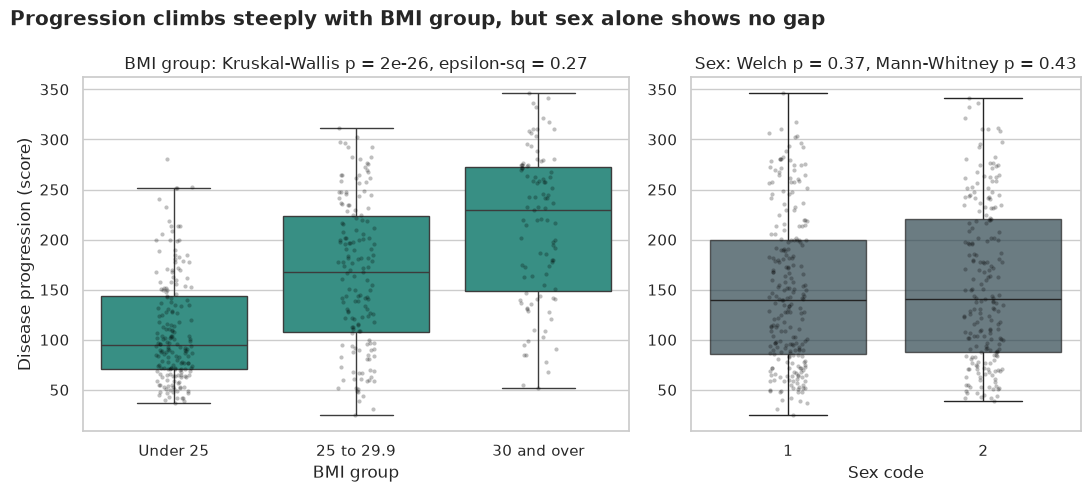

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [1.4, 1]})

sns.boxplot(df, x="bmi_group", y="progression", color=TEAL, fliersize=0, ax=axes[0])
sns.stripplot(df, x="bmi_group", y="progression", color="black", alpha=0.25, size=3, ax=axes[0])
axes[0].set_xlabel("BMI group")
axes[0].set_ylabel("Disease progression (score)")
axes[0].set_title(f"BMI group: Kruskal-Wallis p = {p_kw:.0e}, epsilon-sq = {epsilon_sq:.2f}")

by_sex = df.assign(sex=df["sex"].astype(int))
sns.boxplot(by_sex, x="sex", y="progression", color=NAVY, fliersize=0, ax=axes[1],
            boxprops={"alpha": 0.7})
sns.stripplot(by_sex, x="sex", y="progression", color="black", alpha=0.25, size=3, ax=axes[1])
axes[1].set_xlabel("Sex code")
axes[1].set_ylabel("")
axes[1].set_title(f"Sex: Welch p = {welch.pvalue:.2f}, Mann-Whitney p = {mwu.pvalue:.2f}")

fig.suptitle("Progression climbs steeply with BMI group, but sex alone shows no gap",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "03_bmi_and_sex.png", dpi=150)
plt.show()

**How to read this.** Left: the boxes step upward and barely overlap at the extremes, which is what a large effect looks like. Right: the two sex boxes sit at the same height with the same spread, which is what "no difference" looks like. The dots show every patient behind each box.

### Question 4: Odds ratios, the language doctors use

*What:* so far we have talked about *scores*. Doctors often ask a yes/no question instead: "is this patient at higher risk?" To make that, we label a patient **"high progression"** if their score is above the **median** (140.5), which splits the patients exactly 50/50.

> *Honest note:* squashing a number into yes/no **throws information away**. We do it here only to teach **odds ratios**, a very common way to report results. The regression models in sections 6 and 7 keep the full numbers.

**Odds** are *chance of yes ÷ chance of no*. If 3 out of 4 patients are "high", the odds are 3 to 1 = 3. The **odds ratio (OR)** compares two groups' odds: OR = 1 means no difference, OR = 2 means twice the odds, OR = 0.5 means half. **H₀:** OR = 1. We use **Fisher's exact test**, which is valid even for small counts, and a 95% confidence interval for the OR. Our comparison: **obese (BMI ≥ 30) vs not obese**.

In [10]:
df["high_progression"] = (df["progression"] > df["progression"].median()).astype(int)
df["obese"] = (df["bmi"] >= 30).astype(int)

table = pd.crosstab(df["obese"], df["high_progression"])
table.index = ["Not obese (BMI < 30)", "Obese (BMI >= 30)"]
table.columns = ["Below median", "Above median"]

# Rows: obese first, then not obese; columns: above median first (the "yes" outcome).
counts = np.array([[table.iloc[1, 1], table.iloc[1, 0]], [table.iloc[0, 1], table.iloc[0, 0]]])
odds_obese, odds_other = counts[0, 0] / counts[0, 1], counts[1, 0] / counts[1, 1]
odds_ratio = stats.contingency.odds_ratio(counts, kind="sample")
or_ci = odds_ratio.confidence_interval(0.95)
p_fisher = stats.fisher_exact(counts)[1]

display(table)
print(f"Odds of above-median progression: obese = {odds_obese:.2f}, not obese = {odds_other:.2f}")
print(f"Odds ratio = {odds_ratio.statistic:.1f}, 95% CI [{or_ci.low:.1f}, {or_ci.high:.1f}], "
      f"Fisher exact p = {p_fisher:.0e}")

,Below median,Above median
Not obese (BMI < 30),201,142
Obese (BMI >= 30),20,79


Odds of above-median progression: obese = 3.95, not obese = 0.71
Odds ratio = 5.6, 95% CI [3.3, 9.6], Fisher exact p = 1e-11


**How to read this.** Among obese patients, 79 had above-median progression and 20 did not, so their odds are **3.95**. Among non-obese patients it is 142 vs 201, odds of **0.71**. Dividing gives an **odds ratio of about 5.6**, with a 95% CI of roughly **3.3 to 9.6**. The interval is far from 1 and Fisher's p ≈ 1e-11, so we **reject H₀**: obese patients have several times the odds of being in the faster-progressing half. The interval is wide, because only 99 patients are obese, so "about 5.6" really means "somewhere from 3 to 10".

## 6. Measurements together, and why some of them confuse each other

So far every measurement was judged alone. But the gauges overlap: a patient with a high cholesterol reading usually has a high LDL reading too. Two things can go wrong when we put overlapping gauges in the same model, so we need to look at the overlap first.

### Collinearity: gauges that are near-copies

*What:* the heat-map shows how strongly the predictors correlate with *each other*. **Why it matters:** if `s1` and `s2` move almost in lockstep, a model cannot tell which of the two deserves the credit, so the individual credit assigned to each becomes wobbly and unreliable (even though the model as a whole predicts fine). The standard measure is the **variance inflation factor (VIF)**: how much a coefficient's uncertainty is inflated by overlap with the other predictors. Rules of thumb: below 5 is fine, above 10 is a serious problem.

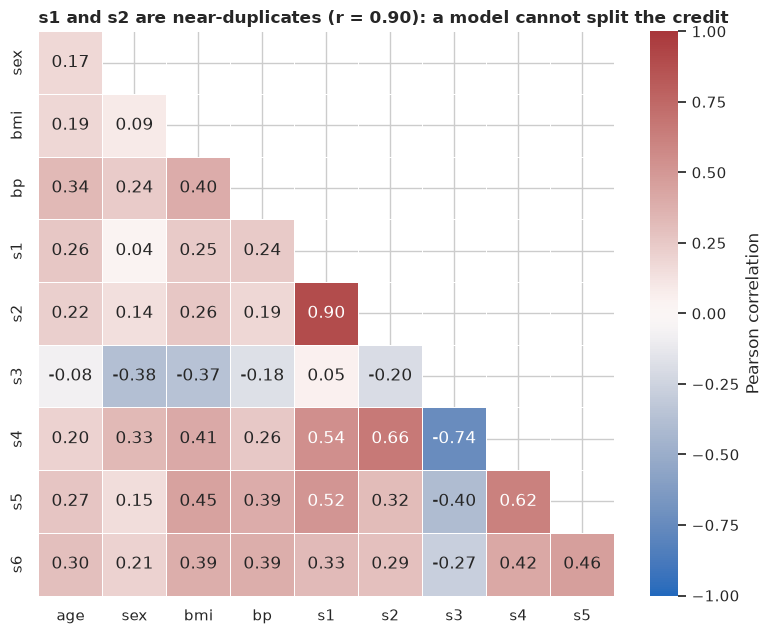

,s1,s2,s3,s5,s4,bmi,s6,bp,sex,age
VIF,59.2,39.2,15.4,10.1,8.9,1.5,1.5,1.5,1.3,1.2


In [11]:
corr_matrix = df[FEATURES].corr().iloc[1:, :-1]  # drop the empty first row and last column
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
r_s1_s2 = df[FEATURES].corr().loc["s1", "s2"]
ax.set_title(f"s1 and s2 are near-duplicates (r = {r_s1_s2:.2f}): a model cannot split the credit",
             loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "04_predictor_correlations.png", dpi=150)
plt.show()

design = sm.add_constant(df[FEATURES].assign(sex=(df["sex"] == 2).astype(int)))
vif = pd.Series(
    {
        name: variance_inflation_factor(design.values, i)
        for i, name in enumerate(design.columns)
        if name != "const"
    },
    name="VIF",
).sort_values(ascending=False)
vif.round(1).to_frame().T

**How to read this.** `s1` (total cholesterol) and `s2` (LDL) correlate at **0.90**, and `s3` (HDL) and `s4` (ratio) at **−0.74**, which makes sense: `s4` is *built from* cholesterol and HDL. The VIFs say the same thing: **`s1` ≈ 59, `s2` ≈ 39, `s3` ≈ 15, `s5` ≈ 10, `s4` ≈ 9**, all in the danger zone, while `age`, `sex`, `bmi`, `bp` and `s6` are all below 2. The cholesterol family is, in effect, one gauge measured five ways.

### Putting everything in one model: adjusted effects

*What:* a **multiple linear regression** estimates each measurement's effect **while holding the others fixed**: "among patients with the same BMI, blood pressure and so on, what does one more unit of *this* measurement add?". We fit two versions with `statsmodels` (which reports confidence intervals and p-values):

- **OLS** for the actual score. Each coefficient says "points of progression per **1 standard deviation** of the measurement" (we z-score the nine numeric columns so effects are comparable). Sex is a 0/1 indicator: code 2 vs code 1.
- **Logistic regression** for the yes/no "high progression" label. It reports **odds ratios per 1 SD**, the multi-variable version of question 4.

> This step is for *explaining*, not for forecasting, so scaling the full dataset here is fine. It isn't leakage because no prediction is being tested. We take care of leakage in section 7.

In [12]:
Z = df[FEATURES].copy()
numeric = [c for c in FEATURES if c != "sex"]
Z[numeric] = (Z[numeric] - Z[numeric].mean()) / Z[numeric].std()
Z["sex_2"] = (df["sex"] == 2).astype(int)
Z = sm.add_constant(Z.drop(columns="sex"))

ols = sm.OLS(df["progression"], Z).fit()
logit = sm.Logit(df["high_progression"], Z).fit(disp=0)

ols_ci = ols.conf_int()
logit_ci = np.exp(logit.conf_int())
adjusted = pd.DataFrame({
    "coef_per_SD": ols.params, "coef_low": ols_ci[0], "coef_high": ols_ci[1], "p_ols": ols.pvalues,
    "odds_ratio": np.exp(logit.params), "or_low": logit_ci[0], "or_high": logit_ci[1],
    "p_logit": logit.pvalues,
}).drop(index="const").sort_values("coef_per_SD")
print(f"OLS R-squared = {ols.rsquared:.2f} (adjusted {ols.rsquared_adj:.2f})")
adjusted.style.format({"coef_per_SD": "{:+.1f}", "coef_low": "{:+.1f}", "coef_high": "{:+.1f}",
                       "p_ols": "{:.3f}", "odds_ratio": "{:.2f}", "or_low": "{:.2f}",
                       "or_high": "{:.2f}", "p_logit": "{:.3f}"})

OLS R-squared = 0.52 (adjusted 0.51)


,coef_per_SD,coef_low,coef_high,p_ols,odds_ratio,or_low,or_high,p_logit
s1,-37.7,-76.7,+1.3,0.058,0.21,0.02,1.85,0.159
sex_2,-22.9,-34.3,-11.4,0.000,0.33,0.18,0.58,0.000
age,-0.5,-6.1,+5.1,0.867,1.05,0.81,1.36,0.710
s6,+3.2,-3.0,+9.4,0.306,1.00,0.74,1.35,0.984
s3,+4.8,-15.1,+24.7,0.635,0.98,0.34,2.81,0.966
s4,+8.4,-6.7,+23.5,0.273,1.04,0.49,2.21,0.916
bp,+15.4,+9.3,+21.6,0.000,1.73,1.30,2.32,0.000
s2,+22.7,-9.0,+54.4,0.160,2.96,0.47,18.85,0.250
bmi,+24.8,+18.5,+31.0,0.000,1.93,1.42,2.63,0.000
s5,+35.8,+19.7,+51.9,0.000,4.09,1.65,10.15,0.002


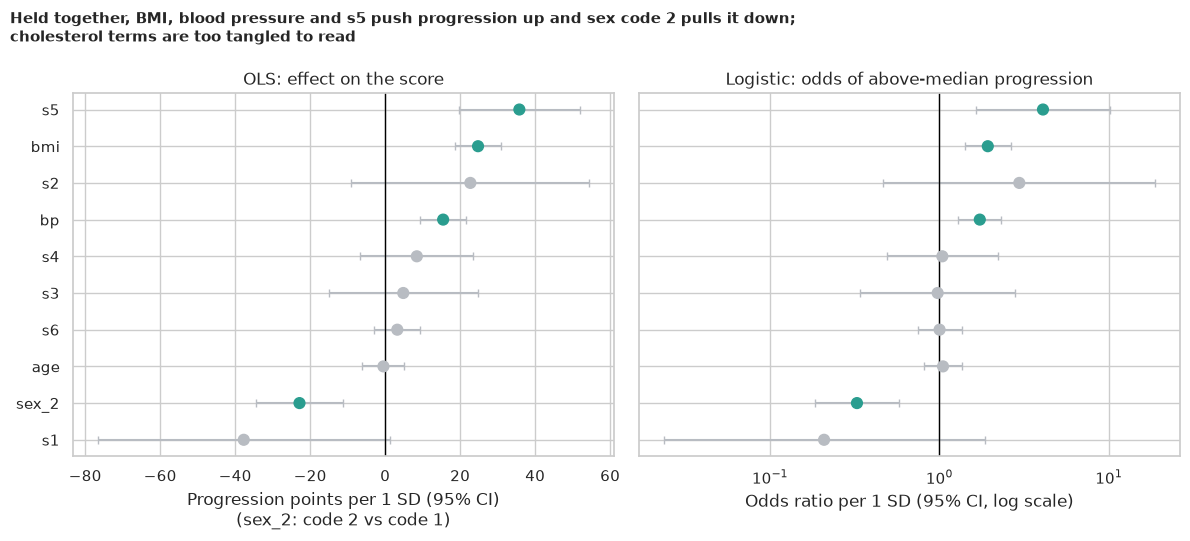

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
ypos = np.arange(len(adjusted))
sig_ols = adjusted["p_ols"] < 0.05
sig_log = adjusted["p_logit"] < 0.05

axes[0].errorbar(adjusted["coef_per_SD"], ypos,
                 xerr=[adjusted["coef_per_SD"] - adjusted["coef_low"],
                       adjusted["coef_high"] - adjusted["coef_per_SD"]],
                 fmt="none", ecolor=GREY, capsize=3)
axes[0].scatter(adjusted["coef_per_SD"], ypos, c=np.where(sig_ols, TEAL, GREY), s=60, zorder=3)
axes[0].axvline(0, color="black", lw=1)
axes[0].set_yticks(ypos, adjusted.index)
axes[0].set_xlabel("Progression points per 1 SD (95% CI)\n(sex_2: code 2 vs code 1)")
axes[0].set_title("OLS: effect on the score")

axes[1].errorbar(adjusted["odds_ratio"], ypos,
                 xerr=[adjusted["odds_ratio"] - adjusted["or_low"],
                       adjusted["or_high"] - adjusted["odds_ratio"]],
                 fmt="none", ecolor=GREY, capsize=3)
axes[1].scatter(adjusted["odds_ratio"], ypos, c=np.where(sig_log, TEAL, GREY), s=60, zorder=3)
axes[1].axvline(1, color="black", lw=1)
axes[1].set_xscale("log")
axes[1].set_xlabel("Odds ratio per 1 SD (95% CI, log scale)")
axes[1].set_title("Logistic: odds of above-median progression")

fig.suptitle("Held together, BMI, blood pressure and s5 push progression up and sex code 2 "
             "pulls it down;\ncholesterol terms are too tangled to read",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_adjusted_effects.png", dpi=150)
plt.show()

**How to read this.** Teal dots are significant at the 5% level, grey are not. The vertical line marks "no effect" (0 points on the left, OR = 1 on the right).

- **Significant, with clear direction: `bmi`, `bp`, `s5` and `sex_2`.** Per 1 SD (about 4.4 BMI units, 13.8 mm Hg and 0.5 log-units of s5), progression rises by about **+25 points for BMI** (95% CI roughly 19 to 31), **+15 for blood pressure** (9 to 22) and **+36 for s5** (20 to 52). The matching odds ratios per SD are about **1.9, 1.7 and 4.1**.
- **Everything else is unclear after adjustment**, including `s1` through `s4`, `s6` and `age`. Look at the cholesterol family: `s1` has a negative point estimate (−38) and `s2` a positive one (+23), and their intervals are enormous (−77 to +1 and −9 to +54; the OR for `s2` spans 0.47 to 18.8). That is **collinearity at work**: the model cannot separate near-copies, so it hands out large, opposite credits that cancel. Don't read those as real effects. This also explains the difference from section 4, where `s1` and `s2` *were* significantly correlated on their own: alone they carry a signal, together they fight over the same one.
- **The sex surprise.** On its own, sex showed no link (p = 0.43). Once the other measurements are held fixed, **code 2 has about 23 *fewer* progression points** (95% CI roughly −34 to −11; OR ≈ 0.33). Why? Patients coded 2 have, on average, *higher* blood pressure (98 vs 92 mm Hg) and *higher* s5 (4.72 vs 4.57), which would raise their scores, but their raw average ends up the same as the other group's. Compare two patients of different sex codes **with the same readings**, and a gap appears. Two effects were cancelling out in the raw comparison. This is why a simple two-group test can hide a real pattern, and why "fail to reject" deserves caution.
- **The model explains about half the variation** (R² ≈ 0.52; adjusted 0.51), so the other half is down to things these ten gauges do not capture.

## 7. Forecasting with honest cross-validation

*What:* so far we explained *what is linked to what*. Now the practical question: **how well can we forecast a new patient's progression?** And is a fancy model worth it?

We build a "ladder" of models from lazy to fancy:

1. **Mean baseline:** always predict the average score (152). The bar to beat.
2. **BMI only**, a straight line.
3. **BMI + blood pressure + s5**, the three clearest gauges from section 6.
4. **The same three + sex**, since sex mattered after adjustment.
5. **All ten measurements** (plain linear regression).
6. **Ridge** and **Lasso**, linear models with a "penalty" that shrinks wobbly coefficients; they are the textbook cure for collinearity. The penalty strength is **chosen by cross-validation inside each training fold**.
7. **Gradient boosting** and **random forest**, flexible tree-based models.

**How we avoid cheating (data leakage).** If you scale or tune on *all* the patients first and then split, the test patients have secretly shaped the model, like a student who saw the exam while making study notes. Putting every step **inside** a scikit-learn `Pipeline` means scaling and penalty tuning are re-done on the training patients only, in every fold.

**How we score.** **RMSE** (root mean squared error) is the typical size of a miss, in progression points (*lower is better*). **R²** is the share of the variation explained (1 = perfect; 0 = no better than always guessing the mean). We use **5-fold cross-validation repeated 10 times** (50 train/test splits), and the **Nadeau-Bengio correction** for the confidence intervals: the 50 scores are not independent because the splits reuse mostly the same patients, much like several judges who read the same pages of a report, so a plain interval would be too narrow.

> *A note on the legacy notebook this replaces:* it scored each model on **one random split** (so the ranking changed every run), printed RMSE under the label "MSE", over-penalised Ridge/Lasso with `alpha=50` (making them look worse than plain linear regression at 79 to 80 vs 58.6), and let k-nearest-neighbours memorise the data with `k=1`.

In [14]:
def subset_linear(columns: list[str]) -> Pipeline:
    """Linear regression on selected columns, standardised inside the pipeline.

    Args:
        columns: Feature names to keep.

    Returns:
        Unfitted Pipeline: column selection, scaling, then linear regression.
    """
    return make_pipeline(
        ColumnTransformer([("keep", "passthrough", columns)]),
        StandardScaler(),
        LinearRegression(),
    )


def build_models() -> dict[str, object]:
    """Builds the model ladder. All preprocessing and tuning live inside each model.

    Returns:
        Model name mapped to an unfitted estimator.
    """
    penalties = np.logspace(-3, 3, 50)
    return {
        "Mean baseline": DummyRegressor(),
        "Linear: bmi": subset_linear(["bmi"]),
        "Linear: bmi + bp + s5": subset_linear(["bmi", "bp", "s5"]),
        "Linear: bmi + bp + s5 + sex": subset_linear(["bmi", "bp", "s5", "sex"]),
        "Linear: all 10": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge (tuned)": make_pipeline(StandardScaler(), RidgeCV(alphas=penalties)),
        "Lasso (tuned)": make_pipeline(
            StandardScaler(), LassoCV(cv=5, random_state=SEED, max_iter=20_000)
        ),
        "Gradient boosting": GradientBoostingRegressor(
            max_depth=2, n_estimators=150, learning_rate=0.05, subsample=0.8, random_state=SEED
        ),
        "Random forest": RandomForestRegressor(
            n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1
        ),
    }


def corrected_ci(scores: np.ndarray, n_train: int, n_test: int) -> tuple[float, float, float]:
    """95% CI for a mean CV score using the Nadeau-Bengio variance correction.

    Args:
        scores: Per-split scores.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        Mean, CI lower bound, CI upper bound.
    """
    k = len(scores)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(scores, ddof=1))
    half = stats.t.ppf(0.975, k - 1) * se
    return float(scores.mean()), float(scores.mean() - half), float(scores.mean() + half)


def corrected_paired_p(diff: np.ndarray, n_train: int, n_test: int) -> float:
    """Two-sided p-value for "do two models differ?" on identical splits.

    Args:
        diff: Per-split score differences between two models.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        p-value from the corrected resampled t-test.
    """
    k = len(diff)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(diff, ddof=1))
    return float(2 * stats.t.sf(abs(diff.mean() / se), k - 1))

Now run the cross-validation. Every model sees **exactly the same 50 splits**, which is what allows the *paired* comparison afterwards. For the model features we use sex as a 0/1 indicator (code 2 vs code 1).

In [15]:
X = df[FEATURES].assign(sex=(df["sex"] == 2).astype(int))
y = df["progression"]
cv = RepeatedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
n_test = len(df) // CV_SPLITS
n_train = len(df) - n_test

rmse_scores, rows = {}, {}
for name, model in build_models().items():
    res = cross_validate(model, X, y, cv=cv,
                         scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
    rmse = -res["test_rmse"]
    rmse_scores[name] = rmse
    mean, lo, hi = corrected_ci(rmse, n_train, n_test)
    rows[name] = {"RMSE": mean, "RMSE low": lo, "RMSE high": hi, "R2": res["test_r2"].mean()}

results = pd.DataFrame(rows).T
results.round(3)

,RMSE,RMSE low,RMSE high,R2
Mean baseline,77.079,72.910,81.247,-0.013
Linear: bmi,62.558,59.149,65.966,0.329
Linear: bmi + bp + s5,55.992,52.988,58.996,0.461
Linear: bmi + bp + s5 + sex,55.768,52.614,58.922,0.466
Linear: all 10,54.919,51.687,58.151,0.482
Ridge (tuned),54.960,51.771,58.150,0.481
Lasso (tuned),54.966,51.770,58.162,0.481
Gradient boosting,56.382,53.153,59.610,0.454
Random forest,57.342,54.467,60.216,0.436


**How to read this.** (RMSE: lower is better. R²: higher is better.)

- **Mean baseline:** RMSE ≈ **77**, R² ≈ 0 (it is slightly *negative* on held-out data, which is normal: the training average is a slightly wrong guess for new patients). Every real model has to beat this.
- **BMI alone** already cuts the typical miss to about **63** (R² ≈ 0.33).
- **BMI + blood pressure + s5** gets to about **56** (R² ≈ 0.46), almost all of what the full model manages.
- **All ten measurements:** RMSE ≈ **55** and R² ≈ **0.48**, the best of the lot, but its interval overlaps the three- and four-gauge models heavily.
- **Ridge and Lasso land at the same ≈ 55.** The penalty barely matters for *forecasting*; collinearity mostly hurts *interpretation* (section 6), not predictions.
- **Gradient boosting (≈ 56) and random forest (≈ 57) are not better than a straight line.** With only 442 patients and ten smooth relationships, flexible models have little to find and a lot of noise to chase.

Are those differences real, or just wobble between splits? The paired test settles it.

In [16]:
reference = "Linear: all 10"
comparisons = {}
for name, scores in rmse_scores.items():
    if name == reference:
        continue
    diff = scores - rmse_scores[reference]
    comparisons[name] = {
        "RMSE minus linear-all": diff.mean(),
        "paired p": corrected_paired_p(diff, n_train, n_test),
    }

four_vs_three = (rmse_scores["Linear: bmi + bp + s5 + sex"] - rmse_scores["Linear: bmi + bp + s5"])
print(f"Adding sex to the 3-gauge model: change in RMSE = {four_vs_three.mean():+.2f}, "
      f"paired p = {corrected_paired_p(four_vs_three, n_train, n_test):.2f}")
pd.DataFrame(comparisons).T.style.format({"RMSE minus linear-all": "{:+.2f}", "paired p": "{:.3f}"})

Adding sex to the 3-gauge model: change in RMSE = -0.22, paired p = 0.54


,RMSE minus linear-all,paired p
Mean baseline,+22.16,0.000
Linear: bmi,+7.64,0.000
Linear: bmi + bp + s5,+1.07,0.226
Linear: bmi + bp + s5 + sex,+0.85,0.297
Ridge (tuned),+0.04,0.783
Lasso (tuned),+0.05,0.813
Gradient boosting,+1.46,0.208
Random forest,+2.42,0.061


**How to read this.** Each row compares a model with the full linear model on the same 50 splits (a positive number means *worse* than the full linear model).

- **Mean baseline and BMI-only are clearly worse** (p ≈ 0): the gap is real.
- **Everything else is statistically indistinguishable from the full linear model**: the 3-gauge model (p ≈ 0.23), the 4-gauge model (p ≈ 0.30), Ridge (p ≈ 0.78), Lasso (p ≈ 0.81), gradient boosting (p ≈ 0.21) and random forest (p ≈ 0.06, the closest to a real difference, and in the *wrong* direction for the fancy model).
- **Sex: significant, but barely useful.** Section 6 found a clear sex effect (p < 0.001) once the other readings were fixed, yet adding it to the 3-gauge model changes RMSE by only about −0.2 (p ≈ 0.54). **Statistically significant is not the same as predictively useful**: a real effect can be too small to improve forecasts.

So the practical lesson: **three cheap gauges (BMI, blood pressure, s5) forecast almost as well as ten**, and complicated models bring nothing.

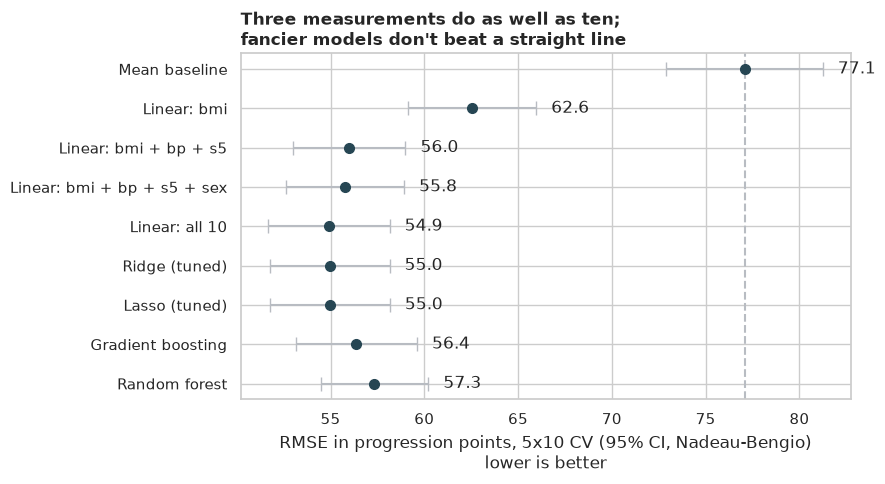

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
names = list(results.index)
ypos = np.arange(len(names))
ax.errorbar(results["RMSE"], ypos,
            xerr=[results["RMSE"] - results["RMSE low"], results["RMSE high"] - results["RMSE"]],
            fmt="o", color=NAVY, ecolor=GREY, capsize=5, markersize=7)
for i, value in enumerate(results["RMSE"]):
    ax.text(results["RMSE high"].iloc[i] + 0.8, i, f"{value:.1f}", va="center")
ax.axvline(results.loc["Mean baseline", "RMSE"], ls="--", color=GREY)
ax.set_yticks(ypos, names)
ax.invert_yaxis()
ax.set_xlabel(
    f"RMSE in progression points, {CV_SPLITS}x{CV_REPEATS} CV (95% CI, Nadeau-Bengio)\n"
    "lower is better"
)
ax.set_title("Three measurements do as well as ten;\nfancier models don't beat a straight line",
             loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "06_model_comparison.png", dpi=150)
plt.show()

**How to read this.** Each dot is a model's typical miss, with its 95% interval. The dashed line is the "always guess the average" baseline. From the third row down, the dots all sit within each other's intervals: that is the visual version of the paired tests.

### What do the forecasts actually look like?

*What:* for the simple 4-gauge model, we use `cross_val_predict` to get a prediction for **every patient from a model that never saw that patient**, then compare with the truth. *How to read:* points on the diagonal are perfect forecasts; the right-hand plot shows the misses (residuals). A good model has misses scattered evenly around 0, with no pattern.

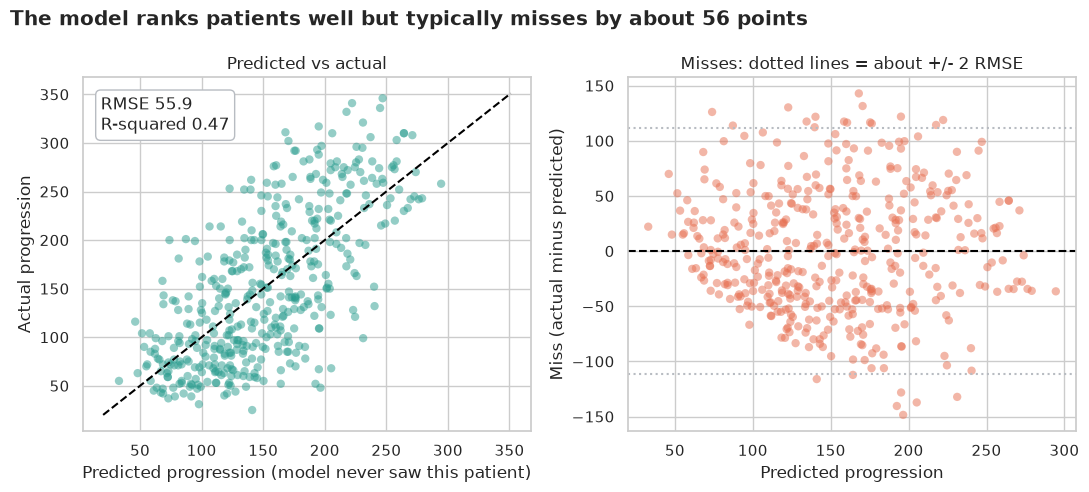

In [18]:
model = subset_linear(["bmi", "bp", "s5", "sex"])
pred = cross_val_predict(model, X, y, cv=KFold(CV_SPLITS, shuffle=True, random_state=SEED))
residuals = y - pred
rmse_oof = np.sqrt((residuals**2).mean())
r2_oof = 1 - (residuals**2).sum() / ((y - y.mean()) ** 2).sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].scatter(pred, y, alpha=0.5, color=TEAL, edgecolor="none")
lims = [min(pred.min(), y.min()) - 5, max(pred.max(), y.max()) + 5]
axes[0].plot(lims, lims, color="black", ls="--")
axes[0].set_xlabel("Predicted progression (model never saw this patient)")
axes[0].set_ylabel("Actual progression")
axes[0].text(0.04, 0.95, f"RMSE {rmse_oof:.1f}\nR-squared {r2_oof:.2f}",
             transform=axes[0].transAxes, va="top",
             bbox={"boxstyle": "round", "fc": "white", "ec": GREY})
axes[0].set_title("Predicted vs actual")

axes[1].scatter(pred, residuals, alpha=0.5, color=ORANGE, edgecolor="none")
axes[1].axhline(0, color="black", ls="--")
axes[1].axhline(2 * rmse_oof, color=GREY, ls=":")
axes[1].axhline(-2 * rmse_oof, color=GREY, ls=":")
axes[1].set_xlabel("Predicted progression")
axes[1].set_ylabel("Miss (actual minus predicted)")
axes[1].set_title("Misses: dotted lines = about +/- 2 RMSE")

fig.suptitle("The model ranks patients well but typically misses by about 56 points",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "07_predicted_vs_actual.png", dpi=150)
plt.show()

**How to read this.** The left plot rises along the diagonal, so the model ranks patients sensibly: high predictions mostly go with high actual scores. But the cloud is wide: a typical miss is about **±56 points** on a scale where the average patient scores 152. The right plot shows no strong curve, which is good, but the misses are **lopsided**: many patients are over-predicted by a modest amount (below the zero line), while a smaller group are under-predicted by a lot (up to about +140). That mirrors the right-skewed shape from section 3: the model struggles most with patients whose disease progressed far more than their baseline readings suggested. The model explains about **47%** of the variation (R² ≈ 0.47).

## 8. 🎯 Takeaways

1. **Nine of the ten measurements correlate with progression, but BMI and s5 lead.** Spearman ρ ≈ +0.56 (BMI) and +0.59 (s5), and `s3` (good cholesterol) is protective at −0.41.
2. **BMI group matters a lot.** Median progression is 95, 168 and 230 across the three WHO bands (Kruskal-Wallis p ≈ 2e-26, ε² ≈ 0.27). Obese patients have an odds ratio of about **5.6** (95% CI 3.3 to 9.6) of being in the faster-progressing half.
3. **Cholesterol measurements are one gauge in disguise.** `s1` and `s2` correlate at 0.90 (VIF 59 and 39), so their separate coefficients are unreadable even though each matters alone.
4. **Sex hides a real effect.** No difference on its own (p ≈ 0.4), but about 23 points *lower* progression for code 2 once readings are held fixed (OR ≈ 0.33). Simple two-group tests can miss patterns that other variables are masking.
5. **Three cheap gauges (BMI, blood pressure, s5) forecast almost as well as ten** (RMSE ≈ 56 vs 55, paired p ≈ 0.23). Ridge, Lasso, boosting and forests added nothing.
6. **Significant is not the same as useful.** Sex is clearly significant in the adjusted model but improves the forecast by only about 0.2 RMSE points (p ≈ 0.54).

## 9. ⚠️ Limitations and edge cases

- **Association, not causation.** Losing weight is not proven to slow progression by these numbers: these are baseline snapshots, and unmeasured things (diet, medication, duration of illness) drive both the readings and the outcome.
- **Small and old.** 442 patients from a 2004 methods paper, with no information on when or where they were recruited. Treatments have changed a lot since.
- **A forecast, but not a precise one.** Typical misses of about 56 points (a bit under 1 standard deviation of the target) mean the model is good for *ranking* patients, not for predicting an exact score for one person.
- **Unknown coding for sex, and a binary view of it.** The dataset does not say which code is which, so the sex findings are about "code 2 vs code 1", nothing more.
- **Median split for odds ratios.** Cutting progression at the median is arbitrary and discards information; a different cut-off would give a different OR.
- **Collinearity.** The cholesterol coefficients cannot be interpreted individually. Prediction is fine; explanation is not.
- **Many looks at one dataset.** Holm corrects the ten correlations and the pairwise BMI tests, but not every comparison one could imagine making.
- **No external check.** All performance numbers come from cross-validation within these 442 patients. A truly independent test would need new patients.

---
*Run `uv run jupyter nbconvert --to html --execute ML/diabetes-risk/diabetes_risk.ipynb --output-dir docs --output ml-diabetes-risk` to rebuild the web version (`docs/ml-diabetes-risk.html`).*